# Check Point 2 — MLP Classificação Binária

## Integrantes
- Nome: Ana Clara Alcântara — RM: 568463
- Nome: Izabely dos Santos — RM: 567088
- Nome: Natalia Alcântara — RM:568570

## Base de dados
**Telco Customer Churn**

## Problema
Classificação binária: prever se um cliente irá cancelar o serviço.

### Target
- Classe positiva (1): Churn = Yes (cliente cancelou)
- Classe negativa (0): Churn = No (cliente permaneceu)


## Fonte
**Telco Customer Churn** — base de exemplo publicada pela IBM e disponibilizada no Kaggle.

- Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn



#Etapa 1 - Entendimento e EDA

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [ ]:
URL_BASE = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

try:
    df = pd.read_csv(URL_BASE)
    print("Base carregada da URL pública.")
except Exception as erro:
    print("Não foi possível baixar da URL:", erro)
    print("Envie o arquivo WA_Fn-UseC_-Telco-Customer-Churn.csv baixado do Kaggle.")
    from google.colab import files
    enviado = files.upload()
    df = pd.read_csv(list(enviado.keys())[0])

print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")


Base carregada da URL pública.
Quantidade de linhas: 7043
Quantidade de colunas: 21


In [ ]:
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# Verificando valores vazios ou suspeitos em TotalCharges

print("Valores vazios em TotalCharges:")
print(df["TotalCharges"].eq(" ").sum())

print("\nValores nulos em TotalCharges:")
print(df["TotalCharges"].isna().sum())

print("\nExemplos de valores de TotalCharges:")
print(df["TotalCharges"].unique()[:20])

Valores vazios em TotalCharges:
11

Valores nulos em TotalCharges:
0

Exemplos de valores de TotalCharges:
['29.85' '1889.5' '108.15' '1840.75' '151.65' '820.5' '1949.4' '301.9'
 '3046.05' '3487.95' '587.45' '326.8' '5681.1' '5036.3' '2686.05'
 '7895.15' '1022.95' '7382.25' '528.35' '1862.9']


In [ ]:
# Tratamento da coluna TotalCharges

df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])

print("Tipo da coluna:", df["TotalCharges"].dtype)
print("Valores ausentes:", df["TotalCharges"].isna().sum())

Tipo da coluna: float64
Valores ausentes: 11


In [ ]:
df[df["TotalCharges"].isna()][
    ["customerID", "tenure", "MonthlyCharges", "Contract", "Churn"]
]

,customerID,tenure,MonthlyCharges,Contract,Churn
488,4472-LVYGI,0,52.55,Two year,No
753,3115-CZMZD,0,20.25,Two year,No
936,5709-LVOEQ,0,80.85,Two year,No
1082,4367-NUYAO,0,25.75,Two year,No
1340,1371-DWPAZ,0,56.05,Two year,No
3331,7644-OMVMY,0,19.85,Two year,No
3826,3213-VVOLG,0,25.35,Two year,No
4380,2520-SGTTA,0,20.00,Two year,No
5218,2923-ARZLG,0,19.70,One year,No
6670,4075-WKNIU,0,73.35,Two year,No


In [ ]:
# Tratamento dos valores ausentes em TotalCharges
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Valores ausentes em TotalCharges:", df["TotalCharges"].isna().sum())
print("Tipo da coluna:", df["TotalCharges"].dtype)

Valores ausentes em TotalCharges: 0
Tipo da coluna: float64


In [ ]:
# Verificando registros duplicados

print("Quantidade de linhas duplicadas:", df.duplicated().sum())

Quantidade de linhas duplicadas: 0


In [ ]:
# Separando as variáveis

target = "Churn"

num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()

# Removendo o target das categóricas
cat_cols.remove(target)

print("Variável alvo:")
print(target)

print("\nVariáveis numéricas:")
print(num_cols)

print("\nVariáveis categóricas:")
print(cat_cols)

print("\nQuantidade de variáveis numéricas:", len(num_cols))
print("Quantidade de variáveis categóricas:", len(cat_cols))

Variável alvo:
Churn

Variáveis numéricas:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variáveis categóricas:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Quantidade de variáveis numéricas: 4
Quantidade de variáveis categóricas: 16


In [ ]:
# Distribuição da variável alvo

print("Quantidade por classe:")
print(df["Churn"].value_counts())

print("\nPercentual por classe:")
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))

Quantidade por classe:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentual por classe:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


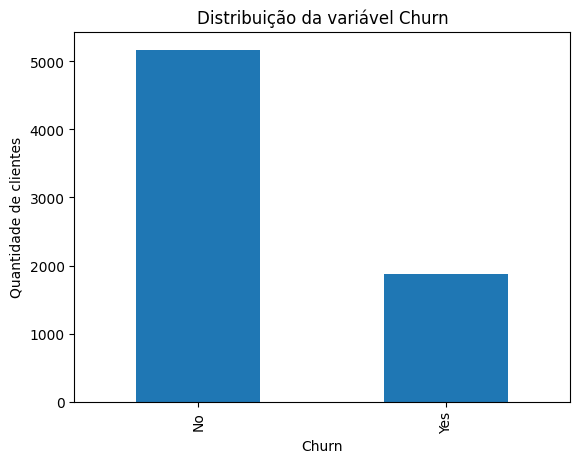

In [ ]:
df["Churn"].value_counts().plot(kind="bar")

plt.title("Distribuição da variável Churn")
plt.xlabel("Churn")
plt.ylabel("Quantidade de clientes")
plt.show()

In [ ]:
# Estatísticas descritivas das variáveis numéricas

df[num_cols].describe().T
#esse .T significa transponse, ele gira a tabela para facilitar a EDA

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


In [ ]:
# Quantidade de categorias por variável categórica

for col in cat_cols:
    print(f"{col}: {df[col].nunique()} categorias")

customerID: 7043 categorias
gender: 2 categorias
Partner: 2 categorias
Dependents: 2 categorias
PhoneService: 2 categorias
MultipleLines: 3 categorias
InternetService: 3 categorias
OnlineSecurity: 3 categorias
OnlineBackup: 3 categorias
DeviceProtection: 3 categorias
TechSupport: 3 categorias
StreamingTV: 3 categorias
StreamingMovies: 3 categorias
Contract: 3 categorias
PaperlessBilling: 2 categorias
PaymentMethod: 4 categorias


In [ ]:
for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- customerID ---
customerID
3186-AJIEK    1
7590-VHVEG    1
5575-GNVDE    1
8775-CEBBJ    1
2823-LKABH    1
             ..
6713-OKOMC    1
1452-KIOVK    1
9305-CDSKC    1
9237-HQITU    1
7795-CFOCW    1
Name: count, Length: 7043, dtype: int64

--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- PhoneService ---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

--- MultipleLines ---
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- OnlineSecurity ---
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- OnlineBackup -

In [ ]:
# Relação entre categorias e Churn

categoricas_analise = [
    "gender",
    "Partner",
    "Dependents",
    "InternetService",
    "Contract",
    "PaymentMethod"
]

for col in categoricas_analise:
    print(f"\n===== {col} =====")
    print(
        pd.crosstab(
            df[col],
            df["Churn"],
            normalize="index"
        ).mul(100).round(2)
    )


===== gender =====
Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16

===== Partner =====
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66

===== Dependents =====
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45

===== InternetService =====
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

===== Contract =====
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83

===== PaymentMethod =====
Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


Insights:


*  Entre os clientes com contrato mensal (Month-to-month), 42,71% apresentaram churn, sendo a maior proporção observada entre os três tipos de contrato.
*   O contrato de dois anos apresentou a menor proporção de churn (2,83%), enquanto o contrato mensal apresentou a maior (42,71%).


*   InternetService: Fiber optic → 41,89% de churn.

*   PaymentMethod: Electronic check → 45,29%, a maior proporção entre os métodos analisados.
*   Credit card (automatic) → 15,24%.
*   gender praticamente não apresenta diferença: 26,92% feminino vs. 26,16% masculino.





In [ ]:
# Estatísticas numéricas separadas por Churn

df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(
    ["mean", "median"]
).round(2)

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

**1. tenure**

Clientes que não cancelaram têm média de 37,57 meses de permanência; os que cancelaram, 17,98 meses. A diferença também aparece na mediana: 38 meses (No) contra 10 meses (Yes). Há uma diferença clara de tempo de permanência entre os grupos.

**2. MonthlyCharges**

Clientes que cancelaram têm cobrança mensal média de 74,44, contra 61,27 entre os que não cancelaram. Ou seja, o grupo Churn = Yes paga mensalidades mais altas.

**3. TotalCharges**

Apesar da mensalidade maior, quem cancelou tem `TotalCharges` menor: média de 1.531,80 contra 2.549,91 e mediana de 703,55 contra 1.679,52. Isso é coerente com o menor tempo de permanência, já que o total acumulado depende de quantos meses o cliente ficou.

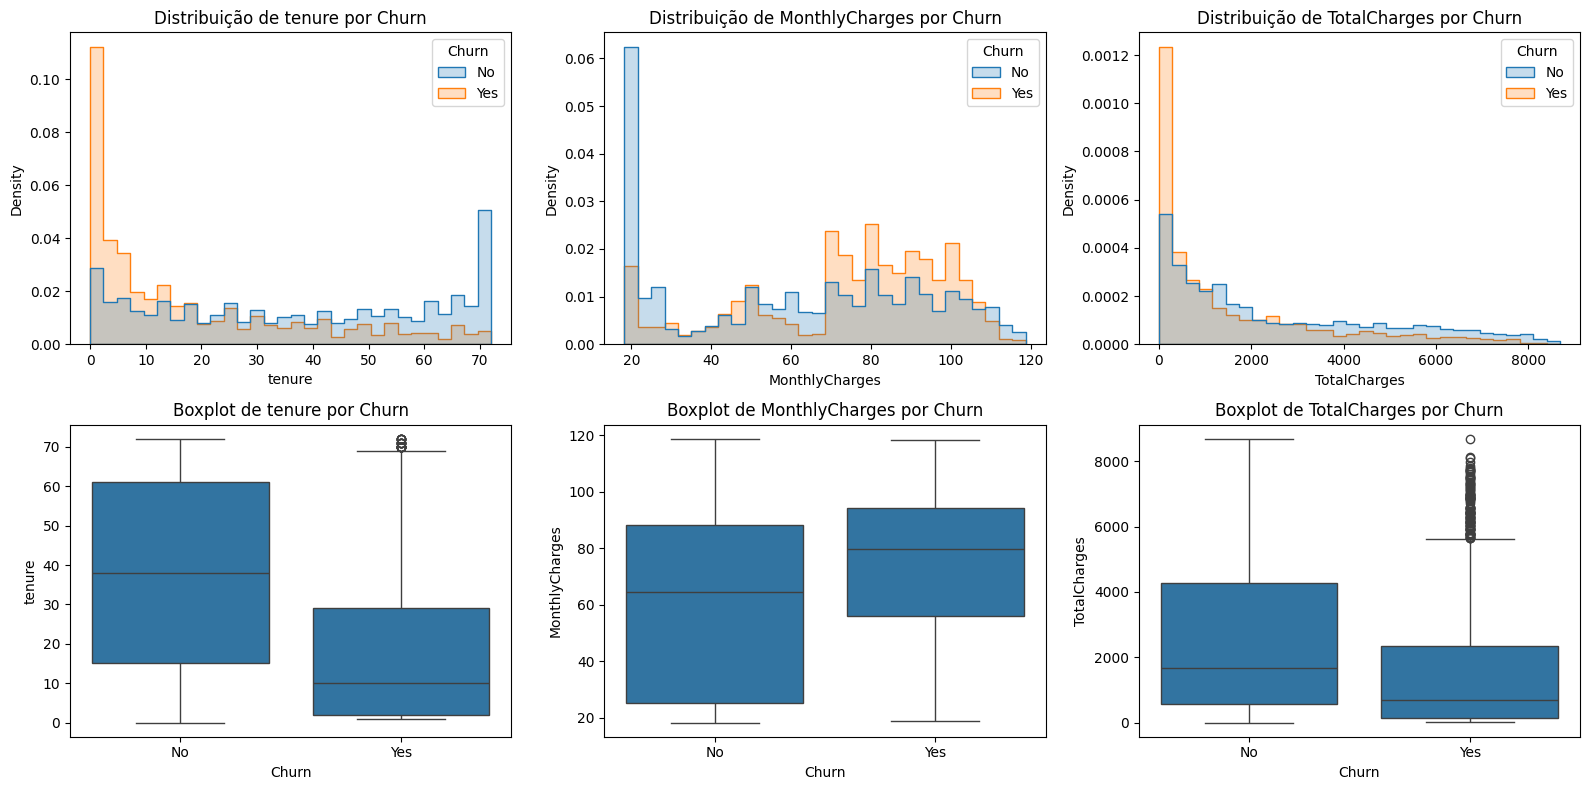

In [ ]:
# Distribuição das variáveis numéricas contínuas por classe de Churn
num_continuas = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num_continuas):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, stat="density",
                 common_norm=False, element="step", ax=axes[0, i])
    axes[0, i].set_title(f"Distribuição de {col} por Churn")
    sns.boxplot(data=df, x="Churn", y=col, ax=axes[1, i])
    axes[1, i].set_title(f"Boxplot de {col} por Churn")
plt.tight_layout()
plt.show()

In [ ]:
# Verificação de outliers pelo critério do IQR (1,5 × IQR)
for col in num_continuas:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    fora = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {fora} valores fora do intervalo do IQR")

tenure: 0 valores fora do intervalo do IQR
MonthlyCharges: 0 valores fora do intervalo do IQR
TotalCharges: 0 valores fora do intervalo do IQR


**Leitura dos gráficos:** clientes com churn se concentram nos primeiros meses de contrato (`tenure` baixo) e em mensalidades mais altas. `TotalCharges` é fortemente assimétrica à direita, o que justifica a padronização antes do treino da rede. Pelo critério do IQR, não há outliers nas três variáveis; os valores altos são clientes antigos ou com muitos serviços, e não erros de registro, por isso nenhum valor foi removido.

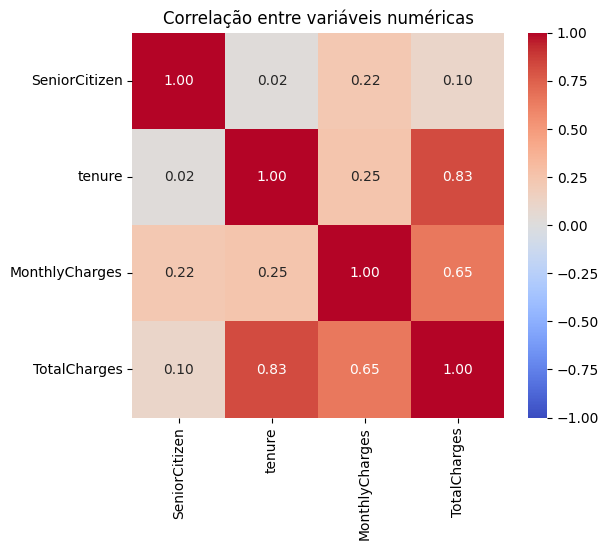

Correlação entre TotalCharges e tenure × MonthlyCharges: 0.9996


In [ ]:
# Correlação entre as variáveis numéricas
corr = df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação entre variáveis numéricas")
plt.show()

# TotalCharges é aproximadamente tenure × MonthlyCharges?
aprox = df["tenure"] * df["MonthlyCharges"]
print("Correlação entre TotalCharges e tenure × MonthlyCharges:",
      round(df["TotalCharges"].corr(aprox), 4))

**Redundância entre variáveis:** `TotalCharges` tem correlação alta com `tenure` (≈ 0,83) e é praticamente o produto `tenure × MonthlyCharges` (correlação ≈ 1,00). Isso indica redundância, não vazamento de dados. As três variáveis foram mantidas porque a MLP lida bem com atributos correlacionados e o enunciado não exige seleção de features; a redundância fica registrada como limitação.

In [ ]:
# Verificando as colunas da base

print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [ ]:
# Verificando possíveis relações diretas com o target

for col in df.columns:
    if col != "Churn":
        qtd_valores = df[col].nunique()

        if qtd_valores <= 10:
            print(f"\n{col} ({qtd_valores} categorias)")
            print(pd.crosstab(df[col], df["Churn"]))


gender (2 categorias)
Churn     No  Yes
gender           
Female  2549  939
Male    2625  930

SeniorCitizen (2 categorias)
Churn            No   Yes
SeniorCitizen            
0              4508  1393
1               666   476

Partner (2 categorias)
Churn      No   Yes
Partner            
No       2441  1200
Yes      2733   669

Dependents (2 categorias)
Churn         No   Yes
Dependents            
No          3390  1543
Yes         1784   326

PhoneService (2 categorias)
Churn           No   Yes
PhoneService            
No             512   170
Yes           4662  1699

MultipleLines (3 categorias)
Churn               No  Yes
MultipleLines              
No                2541  849
No phone service   512  170
Yes               2121  850

InternetService (3 categorias)
Churn              No   Yes
InternetService            
DSL              1962   459
Fiber optic      1799  1297
No               1413   113

OnlineSecurity (3 categorias)
Churn                  No   Yes
OnlineSecurity

Análise de leakage: as variáveis disponíveis foram verificadas quanto à possibilidade de conterem diretamente a informação do target Churn. Não foi identificada nenhuma coluna que represente diretamente o cancelamento do cliente. A coluna customerID foi considerada apenas um identificador e não será utilizada como variável preditora.

In [ ]:
# Removendo o identificador, que não será utilizado como variável preditora

df_modelo = df.drop(columns=["customerID"])

print("Dimensão antes:", df.shape)
print("Dimensão depois:", df_modelo.shape)

print("\nColunas removidas:")
print(["customerID"])

print("\nDimensão final:")
print(df_modelo.shape)

Dimensão antes: (7043, 21)
Dimensão depois: (7043, 20)

Colunas removidas:
['customerID']

Dimensão final:
(7043, 20)


## Conclusões da EDA e decisões de limpeza

### Principais achados

* A base possui **7.043 registros e 21 colunas** inicialmente.
* A variável alvo é `Churn`, com duas classes:

  * `No`: 5.174 clientes (73,46%)
  * `Yes`: 1.869 clientes (26,54%)
* A distribuição do target apresenta **desbalanceamento moderado**, com maior quantidade de clientes que não realizaram churn.
* A variável `TotalCharges` apresentava 11 valores vazios representados por espaços em branco. Esses valores foram identificados como casos de clientes com `tenure = 0` e foram tratados como `0`. A coluna também foi convertida para o tipo numérico.
* Não foram encontrados registros duplicados na base.
* A coluna `customerID` possui 7.043 valores únicos e foi identificada como um **identificador**, não como uma característica preditiva. Por isso, ela foi removida do conjunto de variáveis destinadas ao modelo.
* As categorias `No internet service` e `No phone service` foram mantidas, pois representam situações válidas dos clientes e não valores ausentes.
* Na análise por contrato, clientes com contrato `Month-to-month` apresentaram a maior proporção de churn (42,71%), enquanto clientes com contrato `Two year` apresentaram a menor (2,83%).
* Na variável `InternetService`, a categoria `Fiber optic` apresentou 41,89% de churn, enquanto clientes sem serviço de internet apresentaram 7,40%.
* Na variável `PaymentMethod`, `Electronic check` apresentou a maior proporção de churn entre os métodos analisados, com 45,29%.
* Clientes com churn apresentaram menor tempo médio de permanência (`tenure`) do que clientes sem churn: 17,98 meses contra 37,57 meses.
* Clientes com churn apresentaram maior cobrança mensal média (`MonthlyCharges`): 74,44 contra 61,27.
* Já o `TotalCharges` médio foi menor entre os clientes com churn (1.531,80) do que entre os clientes sem churn (2.549,91), comportamento observado juntamente com o menor tempo de permanência desse grupo.

### Decisões de limpeza

1. Os 11 valores vazios de `TotalCharges` foram convertidos para valores ausentes e posteriormente preenchidos com `0`, considerando que esses registros apresentavam `tenure = 0`.
2. A coluna `TotalCharges` foi convertida para o tipo numérico.
3. Não foram removidas linhas por duplicidade, pois não foram encontrados registros duplicados.
4. A coluna `customerID` foi removida por ser um identificador único e não representar uma característica preditiva do cliente.
5. As categorias `No internet service` e `No phone service` foram mantidas por representarem informações válidas da base.
6. Não foi identificada, durante a análise exploratória realizada, nenhuma variável que representasse diretamente o resultado `Churn`, não sendo encontrada uma coluna com evidência de vazamento direto do target.


# Etapa 2 — Divisão dos dados (treino, validação e teste)

A divisão é feita **antes** de qualquer transformação aprendida (imputação por estatística, padronização, one-hot encoding), para que nenhuma informação da validação ou do teste influencie o pré-processamento. A proporção é 70% treino, 15% validação e 15% teste, estratificada pelo target.

In [ ]:
# Padronização de textos das variáveis categóricas (feita antes do split)
colunas_texto = df_modelo.select_dtypes(include=["object", "string"]).columns.tolist()

conferencia = []
for col in colunas_texto:
    original = df_modelo[col].copy()
    df_modelo[col] = df_modelo[col].str.strip()           # remove espaços no início e no fim
    df_modelo[col] = df_modelo[col].str.replace(r"\s+", " ", regex=True)  # espaços duplicados
    conferencia.append({
        "Variável": col,
        "Categorias": df_modelo[col].nunique(),
        "Valores alterados": int((original != df_modelo[col]).sum()),
        # se houver "Yes" e "yes", o número de categorias cai ao ignorar maiúsculas
        "Variações de maiúsc./minúsc.": df_modelo[col].nunique() - df_modelo[col].str.lower().nunique(),
    })

conferencia = pd.DataFrame(conferencia)
print("Total de valores alterados:", conferencia["Valores alterados"].sum())
print("Total de variações de maiúsculas/minúsculas:", conferencia["Variações de maiúsc./minúsc."].sum())
conferencia

Total de valores alterados: 0
Total de variações de maiúsculas/minúsculas: 0


,Variável,Categorias,Valores alterados,Variações de maiúsc./minúsc.
0,gender,2,0,0
1,Partner,2,0,0
2,Dependents,2,0,0
3,PhoneService,2,0,0
4,MultipleLines,3,0,0
5,InternetService,3,0,0
6,OnlineSecurity,3,0,0
7,OnlineBackup,3,0,0
8,DeviceProtection,3,0,0
9,TechSupport,3,0,0


In [ ]:
from sklearn.model_selection import train_test_split

# Semente fixa usada em todo o projeto
SEED = 42
np.random.seed(SEED)

In [ ]:
# Target em 0/1: classe positiva (1) = Churn "Yes"
df_modelo["Churn"] = df_modelo["Churn"].map({"No": 0, "Yes": 1})
print(df_modelo["Churn"].value_counts())

X = df_modelo.drop(columns=["Churn"])
y = df_modelo["Churn"]

# Listas de variáveis atualizadas (sem customerID e sem o target)
bin_cols = ["SeniorCitizen"]                            # já é 0/1, entra sem padronização
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"] # contínuas, serão padronizadas
cat_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()

print("\nBinárias:", bin_cols)
print("Numéricas:", num_cols)
print(f"Categóricas ({len(cat_cols)}):", cat_cols)
assert len(bin_cols) + len(num_cols) + len(cat_cols) == X.shape[1]

Churn
0    5174
1    1869
Name: count, dtype: int64

Binárias: ['SeniorCitizen']
Numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
# Divisão estratificada 70 / 15 / 15
# 1º passo: 70% treino e 30% temporário
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

# 2º passo: os 30% viram 15% validação e 15% teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

del X_temp, y_temp

In [ ]:
# Conferência: tamanho de cada conjunto e proporção da classe positiva
resumo_split = pd.DataFrame({
    "Conjunto": ["Treino", "Validação", "Teste", "Total"],
    "Amostras": [len(y_train), len(y_val), len(y_test), len(y)],
    "% do total": [len(y_train) / len(y) * 100, len(y_val) / len(y) * 100,
                   len(y_test) / len(y) * 100, 100.0],
    "% Churn = Yes": [y_train.mean() * 100, y_val.mean() * 100,
                      y_test.mean() * 100, y.mean() * 100],
}).round(2)

resumo_split

,Conjunto,Amostras,% do total,% Churn = Yes
0,Treino,4930,70.00,26.53
1,Validação,1056,14.99,26.52
2,Teste,1057,15.01,26.58
3,Total,7043,100.00,26.54


**Resultado da divisão:** treino com 4.930 clientes (70%), validação com 1.056 (15%) e teste com 1.057 (15%). A proporção de churn ficou em torno de 26,5% nos três conjuntos, igual à da base completa, confirmando que a estratificação funcionou.

**Regra a partir daqui:** `X_test` e `y_test` não serão usados em nenhuma etapa de pré-processamento, treino ou escolha de arquitetura. O conjunto de teste só será usado na avaliação final do modelo escolhido.

# Etapa 3 — Pré-processamento sem vazamento de dados

Todas as transformações que aprendem algo dos dados (médias, desvios-padrão e categorias existentes) são **ajustadas somente no conjunto de treino** com `fit_transform` e depois apenas **aplicadas** à validação e ao teste com `transform`. Assim, nenhuma informação da validação ou do teste influencia o pré-processamento.

| Grupo | Variáveis | Transformação | Motivo |
| --- | --- | --- | --- |
| Numéricas contínuas | `tenure`, `MonthlyCharges`, `TotalCharges` | `StandardScaler` (média 0, desvio 1) | Escalas muito diferentes (0–72 meses contra até 8.684 em `TotalCharges`) atrapalham o gradiente da rede |
| Binária numérica | `SeniorCitizen` | Mantida como está (0/1) | Já está na escala adequada |
| Categóricas | 15 colunas de texto | `OneHotEncoder` | A rede só recebe números; o one-hot não cria uma ordem falsa entre as categorias |

In [ ]:
# Conferência: não há valores ausentes em nenhum conjunto
for nome, conjunto in [("Treino", X_train), ("Validação", X_val), ("Teste", X_test)]:
    print(f"{nome}: {conjunto.isna().sum().sum()} valores ausentes")

Treino: 0 valores ausentes
Validação: 0 valores ausentes
Teste: 0 valores ausentes


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("bin", "passthrough", bin_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore",
                              sparse_output=False), cat_cols),
    ]
)

# fit SOMENTE no treino; validação e teste recebem apenas transform
X_train_proc = preprocessador.fit_transform(X_train).astype("float32")
X_val_proc   = preprocessador.transform(X_val).astype("float32")
X_test_proc  = preprocessador.transform(X_test).astype("float32")

y_train_arr = y_train.to_numpy().astype("float32")
y_val_arr   = y_val.to_numpy().astype("float32")
y_test_arr  = y_test.to_numpy().astype("float32")

nomes_features = preprocessador.get_feature_names_out()

print("Colunas antes do pré-processamento:", X_train.shape[1])
print("Colunas depois do pré-processamento:", X_train_proc.shape[1])
print("\nFormato final:")
print("  Treino:   ", X_train_proc.shape)
print("  Validação:", X_val_proc.shape)
print("  Teste:    ", X_test_proc.shape)

Colunas antes do pré-processamento: 19
Colunas depois do pré-processamento: 40

Formato final:
  Treino:    (4930, 40)
  Validação: (1056, 40)
  Teste:     (1057, 40)


In [ ]:
# Verificação: a padronização foi aprendida com o treino
idx_num = list(range(len(num_cols)))

verificacao = pd.DataFrame({
    "Média treino": X_train_proc[:, idx_num].mean(axis=0),
    "Desvio treino": X_train_proc[:, idx_num].std(axis=0),
    "Média validação": X_val_proc[:, idx_num].mean(axis=0),
    "Média teste": X_test_proc[:, idx_num].mean(axis=0),
}, index=num_cols).round(3)

print("Médias e desvios usados pelo StandardScaler (aprendidos no treino):")
print(pd.DataFrame({"média": preprocessador.named_transformers_["num"].mean_,
                    "desvio": preprocessador.named_transformers_["num"].scale_},
                   index=num_cols).round(2))
verificacao

Médias e desvios usados pelo StandardScaler (aprendidos no treino):
                  média   desvio
tenure            32.47    24.64
MonthlyCharges    64.95    30.24
TotalCharges    2301.80  2292.33


,Média treino,Desvio treino,Média validação,Média teste
tenure,-0.0,1.0,-0.034,0.006
MonthlyCharges,-0.0,1.0,0.015,-0.057
TotalCharges,-0.0,1.0,-0.037,-0.027


In [ ]:
# Lista das features finais que entram na rede
pd.DataFrame({"feature": nomes_features})

,feature
0,num__tenure
1,num__MonthlyCharges
2,num__TotalCharges
3,bin__SeniorCitizen
4,cat__gender_Male
5,cat__Partner_Yes
6,cat__Dependents_Yes
7,cat__PhoneService_Yes
8,cat__MultipleLines_No
9,cat__MultipleLines_No phone service


## Tratamento do desbalanceamento

A base tem 26,5% de churn. Sem nenhum ajuste, a rede tende a favorecer a classe majoritária e deixar passar clientes que vão cancelar, o que é o erro mais caro para o negócio (falso negativo: perder o cliente sem tentar retê-lo).

Os pesos de classe são calculados **somente com `y_train`** e aplicados igualmente em **todos** os experimentos, para não interferir na comparação entre arquiteturas.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

USAR_CLASS_WEIGHT = True   # decisão do grupo: mesma configuração em todos os experimentos

pesos = compute_class_weight(class_weight="balanced",
                             classes=np.array([0, 1]), y=y_train_arr)
CLASS_WEIGHT = {0: float(pesos[0]), 1: float(pesos[1])} if USAR_CLASS_WEIGHT else None

print("Pesos calculados no treino:", {k: round(v, 3) for k, v in
                                     {0: pesos[0], 1: pesos[1]}.items()})
print("class_weight usado nos experimentos:", CLASS_WEIGHT)

Pesos calculados no treino: {0: np.float64(0.681), 1: np.float64(1.885)}
class_weight usado nos experimentos: {0: 0.680563224737714, 1: 1.8845565749235473}


Com `class_weight="balanced"`, cada erro na classe positiva (churn) pesa cerca de **2,8 vezes mais** que um erro na classe negativa durante o treino. Isso tende a aumentar o recall da classe positiva, possivelmente com alguma perda de precisão e de acurácia. Esse efeito deve ser lembrado na análise dos resultados: a acurácia não é a métrica principal deste problema.

In [ ]:
# Conferência de categorias raras (calculada só no treino)
freq_min = []
for col in cat_cols:
    proporcoes = X_train[col].value_counts(normalize=True)
    freq_min.append({"Variável": col, "Categoria menos frequente": proporcoes.idxmin(),
                     "% no treino": round(proporcoes.min() * 100, 2)})
freq_min = pd.DataFrame(freq_min).sort_values("% no treino")
freq_min.head()

,Variável,Categoria menos frequente,% no treino
3,PhoneService,No,10.06
4,MultipleLines,No phone service,10.06
12,Contract,One year,20.97
14,PaymentMethod,Credit card (automatic),21.64
7,OnlineBackup,No internet service,21.66


**Categorias raras:** a categoria menos frequente no treino tem cerca de 10% dos registros (`PhoneService = No` e `MultipleLines = No phone service`). Como nenhuma categoria é rara, não foi necessário agrupar categorias em "Outros".

**Colunas redundantes após o one-hot:** as seis colunas `..._No internet service` são idênticas a `InternetService_No`, e `MultipleLines_No phone service` é o inverso de `PhoneService_Yes`. Essa redundância não impede o treino da MLP e foi mantida, mas fica registrada como limitação.

## Resumo da Etapa 3

1. Não havia ausentes nos três conjuntos, então nenhum imputador foi necessário.
2. As numéricas contínuas foram padronizadas com `StandardScaler`, e `SeniorCitizen` foi mantida como 0/1.
3. As 15 categóricas foram transformadas com `OneHotEncoder(drop="if_binary", handle_unknown="ignore")`.
4. Todas as transformações foram **ajustadas somente no treino** e aplicadas à validação e ao teste.
5. A base passou de 19 para 40 colunas.
6. Os pesos de classe foram calculados no treino e serão usados igualmente em todos os experimentos.

# Etapa 4 — Construção das MLPs e experimentos

Todos os experimentos usam **uma única função de treino**, chamada com uma configuração diferente para cada arquitetura. Só muda o que está sendo comparado (largura, profundidade ou função de ativação); todo o resto fica fixo. O conjunto de teste **não é usado** nesta etapa.

In [ ]:
import time
import sklearn
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

# Reprodutibilidade: mesma semente em Python, NumPy e TensorFlow + operações determinísticas
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("Versões usadas no experimento:")
print("  pandas      ", pd.__version__)
print("  numpy       ", np.__version__)
print("  scikit-learn", sklearn.__version__)
print("  tensorflow  ", tf.__version__)
print("  keras       ", keras.__version__)

Versões usadas no experimento:
  pandas       2.2.3
  numpy        2.1.3
  scikit-learn 1.6.1
  tensorflow   2.21.0
  keras        3.13.2


## Configuração fixa de treinamento

Estes parâmetros são **iguais em todos os experimentos**, para que as diferenças de desempenho venham apenas da arquitetura.

In [ ]:
CONFIG = {
    "ativacao_saida": "sigmoid",          # probabilidade da classe positiva (churn)
    "funcao_perda": "binary_crossentropy",
    "otimizador": "Adam",
    "learning_rate": 0.001,
    "epocas_max": 100,
    "batch_size": 32,
    "early_stopping_paciencia": 10,       # para se a val_loss não melhorar por 10 épocas
    "restaurar_melhores_pesos": True,
    "class_weight": CLASS_WEIGHT,         # definido na Etapa 3 (somente com y_train)
    "limiar_decisao": 0.5,
    "inicializacao_pesos": "glorot_uniform (padrão do Keras)",
    "semente": SEED,
}

pd.DataFrame({"Parâmetro": CONFIG.keys(), "Valor": [str(v) for v in CONFIG.values()]})

,Parâmetro,Valor
0,ativacao_saida,sigmoid
1,funcao_perda,binary_crossentropy
2,otimizador,Adam
3,learning_rate,0.001
4,epocas_max,100
5,batch_size,32
6,early_stopping_paciencia,10
7,restaurar_melhores_pesos,True
8,class_weight,"{0: 0.680563224737714, 1: 1.8845565749235473}"
9,limiar_decisao,0.5


## Funções de construção, avaliação e treino

In [ ]:
def construir_mlp(id_exp, camadas, ativacao, n_features):
    """Cria e compila uma MLP com as camadas ocultas informadas e saída sigmoid."""
    modelo = keras.Sequential(name=f"MLP_{id_exp}")
    modelo.add(keras.Input(shape=(n_features,)))
    for i, n_neuronios in enumerate(camadas, start=1):
        modelo.add(keras.layers.Dense(n_neuronios, activation=ativacao, name=f"oculta_{i}"))
    modelo.add(keras.layers.Dense(1, activation=CONFIG["ativacao_saida"], name="saida"))

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=CONFIG["learning_rate"]),
        loss=CONFIG["funcao_perda"],
        metrics=["accuracy"],
    )
    return modelo


def avaliar(modelo, X, y):
    """Loss (sem pesos de classe), métricas da classe positiva e matriz de confusão."""
    loss = modelo.evaluate(X, y, verbose=0)[0]
    prob = modelo.predict(X, verbose=0).ravel()
    pred = (prob >= CONFIG["limiar_decisao"]).astype(int)
    return {
        "loss": loss,
        "acuracia": accuracy_score(y, pred),
        "precisao": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "matriz": confusion_matrix(y, pred, labels=[0, 1]),
    }


def treinar_experimento(id_exp, objetivo, camadas, ativacao):
    """Treina uma arquitetura com a CONFIG fixa e devolve registro, histórico e modelo."""
    keras.utils.set_random_seed(SEED)   # mesma inicialização de pesos e ordem dos batches
    modelo = construir_mlp(id_exp, camadas, ativacao, X_train_proc.shape[1])

    parada = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=CONFIG["early_stopping_paciencia"],
        restore_best_weights=CONFIG["restaurar_melhores_pesos"],
    )

    inicio = time.time()
    historico = modelo.fit(
        X_train_proc, y_train_arr,
        validation_data=(X_val_proc, y_val_arr),
        epochs=CONFIG["epocas_max"],
        batch_size=CONFIG["batch_size"],
        class_weight=CONFIG["class_weight"],
        callbacks=[parada],
        shuffle=True,
        verbose=0,
    )
    duracao = time.time() - inicio

    m_treino = avaliar(modelo, X_train_proc, y_train_arr)
    m_val = avaliar(modelo, X_val_proc, y_val_arr)

    registro = {
        "ID": id_exp,
        "Objetivo": objetivo,
        "Nº camadas ocultas": len(camadas),
        "Neurônios por camada": " - ".join(map(str, camadas)),
        "Ativação": ativacao,
        "Parâmetros": modelo.count_params(),
        "Épocas treinadas": len(historico.history["loss"]),
        "Melhor época": int(np.argmin(historico.history["val_loss"])) + 1,
        "Tempo (s)": round(duracao, 1),
        "Loss treino": m_treino["loss"],
        "Loss val.": m_val["loss"],
        "Acurácia treino": m_treino["acuracia"],
        "Acurácia": m_val["acuracia"],
        "Precisão": m_val["precisao"],
        "Recall": m_val["recall"],
        "F1 treino": m_treino["f1"],
        "F1": m_val["f1"],
        "Matriz val.": m_val["matriz"],
    }
    return registro, historico.history, modelo

## Plano de experimentos

Os 7 experimentos do enunciado (E1 a E7) mais dois extras (E8 e E9). E4 e E5 mudam profundidade **e** largura ao mesmo tempo; E8 e E9 mantêm 32 neurônios por camada, como E2, e mudam **só** o número de camadas, isolando o efeito da profundidade.

| Comparação | Experimentos | O que muda |
| --- | --- | --- |
| Largura | E1 → E2 → E3 | 16, 32, 64 neurônios em 1 camada |
| Profundidade (enunciado) | E2 → E4 → E5 | 1, 2, 3 camadas (largura também muda) |
| Profundidade isolada | E2 → E8 → E9 | 1, 2, 3 camadas de 32 neurônios |
| Ativação | E2 → E6 → E7 | ReLU, tanh, sigmoid com a mesma arquitetura |

In [ ]:
EXPERIMENTOS = [
    # (ID, objetivo, camadas ocultas, ativação)
    ("E1", "Referência",            [16],          "relu"),
    ("E2", "Largura",               [32],          "relu"),
    ("E3", "Largura",               [64],          "relu"),
    ("E4", "Profundidade",          [32, 16],      "relu"),
    ("E5", "Profundidade",          [64, 32, 16],  "relu"),
    ("E6", "Ativação",              [32],          "tanh"),
    ("E7", "Ativação",              [32],          "sigmoid"),
    ("E8", "Profundidade isolada",  [32, 32],      "relu"),
    ("E9", "Profundidade isolada",  [32, 32, 32],  "relu"),
]

## Execução dos experimentos

In [ ]:
registros, historicos, modelos = [], {}, {}

for id_exp, objetivo, camadas, ativacao in EXPERIMENTOS:
    registro, historico, modelo = treinar_experimento(id_exp, objetivo, camadas, ativacao)
    registros.append(registro)
    historicos[id_exp] = historico
    modelos[id_exp] = modelo
    print(f"{id_exp} | {str(camadas):<14} {ativacao:<8} | épocas: {registro['Épocas treinadas']:>3} "
          f"(melhor {registro['Melhor época']:>3}) | val loss: {registro['Loss val.']:.4f} "
          f"| val F1: {registro['F1']:.4f} | recall: {registro['Recall']:.4f}")

resultados = pd.DataFrame(registros).set_index("ID")

E1 | [16]           relu     | épocas:  32 (melhor  22) | val loss: 0.5125 | val F1: 0.6237 | recall: 0.8286
E2 | [32]           relu     | épocas:  43 (melhor  33) | val loss: 0.5069 | val F1: 0.6361 | recall: 0.8179
E3 | [64]           relu     | épocas:  28 (melhor  18) | val loss: 0.4982 | val F1: 0.6183 | recall: 0.8071
E4 | [32, 16]       relu     | épocas:  37 (melhor  27) | val loss: 0.5018 | val F1: 0.6149 | recall: 0.7643
E5 | [64, 32, 16]   relu     | épocas:  18 (melhor   8) | val loss: 0.5011 | val F1: 0.6192 | recall: 0.8071
E6 | [32]           tanh     | épocas:  78 (melhor  68) | val loss: 0.5000 | val F1: 0.6323 | recall: 0.8107
E7 | [32]           sigmoid  | épocas: 100 (melhor 100) | val loss: 0.5037 | val F1: 0.6253 | recall: 0.8286
E8 | [32, 32]       relu     | épocas:  20 (melhor  10) | val loss: 0.5008 | val F1: 0.6362 | recall: 0.8214
E9 | [32, 32, 32]   relu     | épocas:  18 (melhor   8) | val loss: 0.4953 | val F1: 0.6236 | recall: 0.7929


## Registro dos experimentos

Tabela com os parâmetros de cada experimento, como pede a Seção 4.4 do enunciado. Os parâmetros fixos estão na tabela `CONFIG` acima.

In [ ]:
registro_exp = resultados[["Objetivo", "Nº camadas ocultas", "Neurônios por camada", "Ativação",
                           "Parâmetros", "Épocas treinadas", "Melhor época", "Tempo (s)"]].copy()
registro_exp["Ativação saída"] = CONFIG["ativacao_saida"]
registro_exp["Perda"] = CONFIG["funcao_perda"]
registro_exp["Otimizador"] = f'{CONFIG["otimizador"]} (lr={CONFIG["learning_rate"]})'
registro_exp["Batch"] = CONFIG["batch_size"]
registro_exp

,Objetivo,Nº camadas ocultas,Neurônios por camada,Ativação,Parâmetros,Épocas treinadas,Melhor época,Tempo (s),Ativação saída,Perda,Otimizador,Batch
ID,,,,,,,,,,,,
E1,Referência,1,16,relu,673,32,22,15.9,sigmoid,binary_crossentropy,Adam (lr=0.001),32
E2,Largura,1,32,relu,1345,43,33,20.4,sigmoid,binary_crossentropy,Adam (lr=0.001),32
E3,Largura,1,64,relu,2689,28,18,13.9,sigmoid,binary_crossentropy,Adam (lr=0.001),32
E4,Profundidade,2,32 - 16,relu,1857,37,27,18.0,sigmoid,binary_crossentropy,Adam (lr=0.001),32
E5,Profundidade,3,64 - 32 - 16,relu,5249,18,8,10.6,sigmoid,binary_crossentropy,Adam (lr=0.001),32
E6,Ativação,1,32,tanh,1345,78,68,37.4,sigmoid,binary_crossentropy,Adam (lr=0.001),32
E7,Ativação,1,32,sigmoid,1345,100,100,47.3,sigmoid,binary_crossentropy,Adam (lr=0.001),32
E8,Profundidade isolada,2,32 - 32,relu,2401,20,10,10.8,sigmoid,binary_crossentropy,Adam (lr=0.001),32
E9,Profundidade isolada,3,32 - 32 - 32,relu,3457,18,8,10.6,sigmoid,binary_crossentropy,Adam (lr=0.001),32


## Tabela comparativa (validação)

Tabela obrigatória da Seção 9, com colunas extras para apoiar a análise de overfitting (loss e F1 de treino e a diferença entre treino e validação).

In [ ]:
tabela = resultados[["Neurônios por camada", "Ativação", "Parâmetros",
                     "Loss treino", "Loss val.", "Acurácia", "Precisão", "Recall",
                     "F1 treino", "F1"]].copy()
tabela.insert(0, "Camadas", resultados["Nº camadas ocultas"])
tabela["Gap F1 (treino − val.)"] = tabela["F1 treino"] - tabela["F1"]

tabela.round(4)

,Camadas,Neurônios por camada,Ativação,Parâmetros,Loss treino,Loss val.,Acurácia,Precisão,Recall,F1 treino,F1,Gap F1 (treino − val.)
ID,,,,,,,,,,,,
E1,1,16,relu,673,0.4831,0.5125,0.7348,0.5000,0.8286,0.6382,0.6237,0.0145
E2,1,32,relu,1345,0.4599,0.5069,0.7519,0.5205,0.8179,0.6538,0.6361,0.0177
E3,1,64,relu,2689,0.4542,0.4982,0.7358,0.5011,0.8071,0.6508,0.6183,0.0325
E4,2,32 - 16,relu,1857,0.4327,0.5018,0.7462,0.5144,0.7643,0.6604,0.6149,0.0454
E5,3,64 - 32 - 16,relu,5249,0.4623,0.5011,0.7367,0.5022,0.8071,0.6525,0.6192,0.0333
E6,1,32,tanh,1345,0.4530,0.5000,0.7500,0.5183,0.8107,0.6579,0.6323,0.0256
E7,1,32,sigmoid,1345,0.4779,0.5037,0.7367,0.5022,0.8286,0.6396,0.6253,0.0143
E8,2,32 - 32,relu,2401,0.4622,0.5008,0.7509,0.5192,0.8214,0.6505,0.6362,0.0143
E9,3,32 - 32 - 32,relu,3457,0.4570,0.4953,0.7462,0.5139,0.7929,0.6476,0.6236,0.0240


In [ ]:
# Matrizes de confusão na validação: [[VN, FP], [FN, VP]]
for id_exp, linha in resultados.iterrows():
    (vn, fp), (fn, vp) = linha["Matriz val."]
    print(f"{id_exp}: VN={vn:>4}  FP={fp:>4}  FN={fn:>4}  VP={vp:>4}")

E1: VN= 544  FP= 232  FN=  48  VP= 232
E2: VN= 565  FP= 211  FN=  51  VP= 229
E3: VN= 551  FP= 225  FN=  54  VP= 226
E4: VN= 574  FP= 202  FN=  66  VP= 214
E5: VN= 552  FP= 224  FN=  54  VP= 226
E6: VN= 565  FP= 211  FN=  53  VP= 227
E7: VN= 546  FP= 230  FN=  48  VP= 232
E8: VN= 563  FP= 213  FN=  50  VP= 230
E9: VN= 566  FP= 210  FN=  58  VP= 222


## Resumo da Etapa 4

1. Foram treinadas 9 arquiteturas de MLP com a mesma configuração fixa (Adam, lr 0,001, batch 32, até 100 épocas com early stopping, `binary_crossentropy`, saída sigmoid, mesmos pesos de classe e mesma semente).
2. Todas usaram exatamente os mesmos conjuntos de treino e validação; o teste não foi usado.
3. Para cada experimento foram registrados os parâmetros, as épocas treinadas, a loss e as métricas de treino e de validação e a matriz de confusão.
4. Os modelos, históricos e resultados ficam guardados em `modelos`, `historicos` e `resultados` para a análise da Etapa 5 (gráficos, comparação e escolha da arquitetura).

# Etapa 5 — Análise comparativa e seleção da arquitetura

A escolha é feita **exclusivamente com a validação**. O teste continua sem uso até a Etapa 6.

## Curvas de aprendizado

A loss de treino exibida é a **ponderada** pelos pesos de classe (a que o Keras otimiza); a de validação não tem pesos. Por isso a comparação numérica de treino × validação é feita com a tabela da Etapa 4, que recalcula a loss de treino sem pesos. As curvas servem para ver a **tendência**: onde a validação para de melhorar e se ela volta a subir.

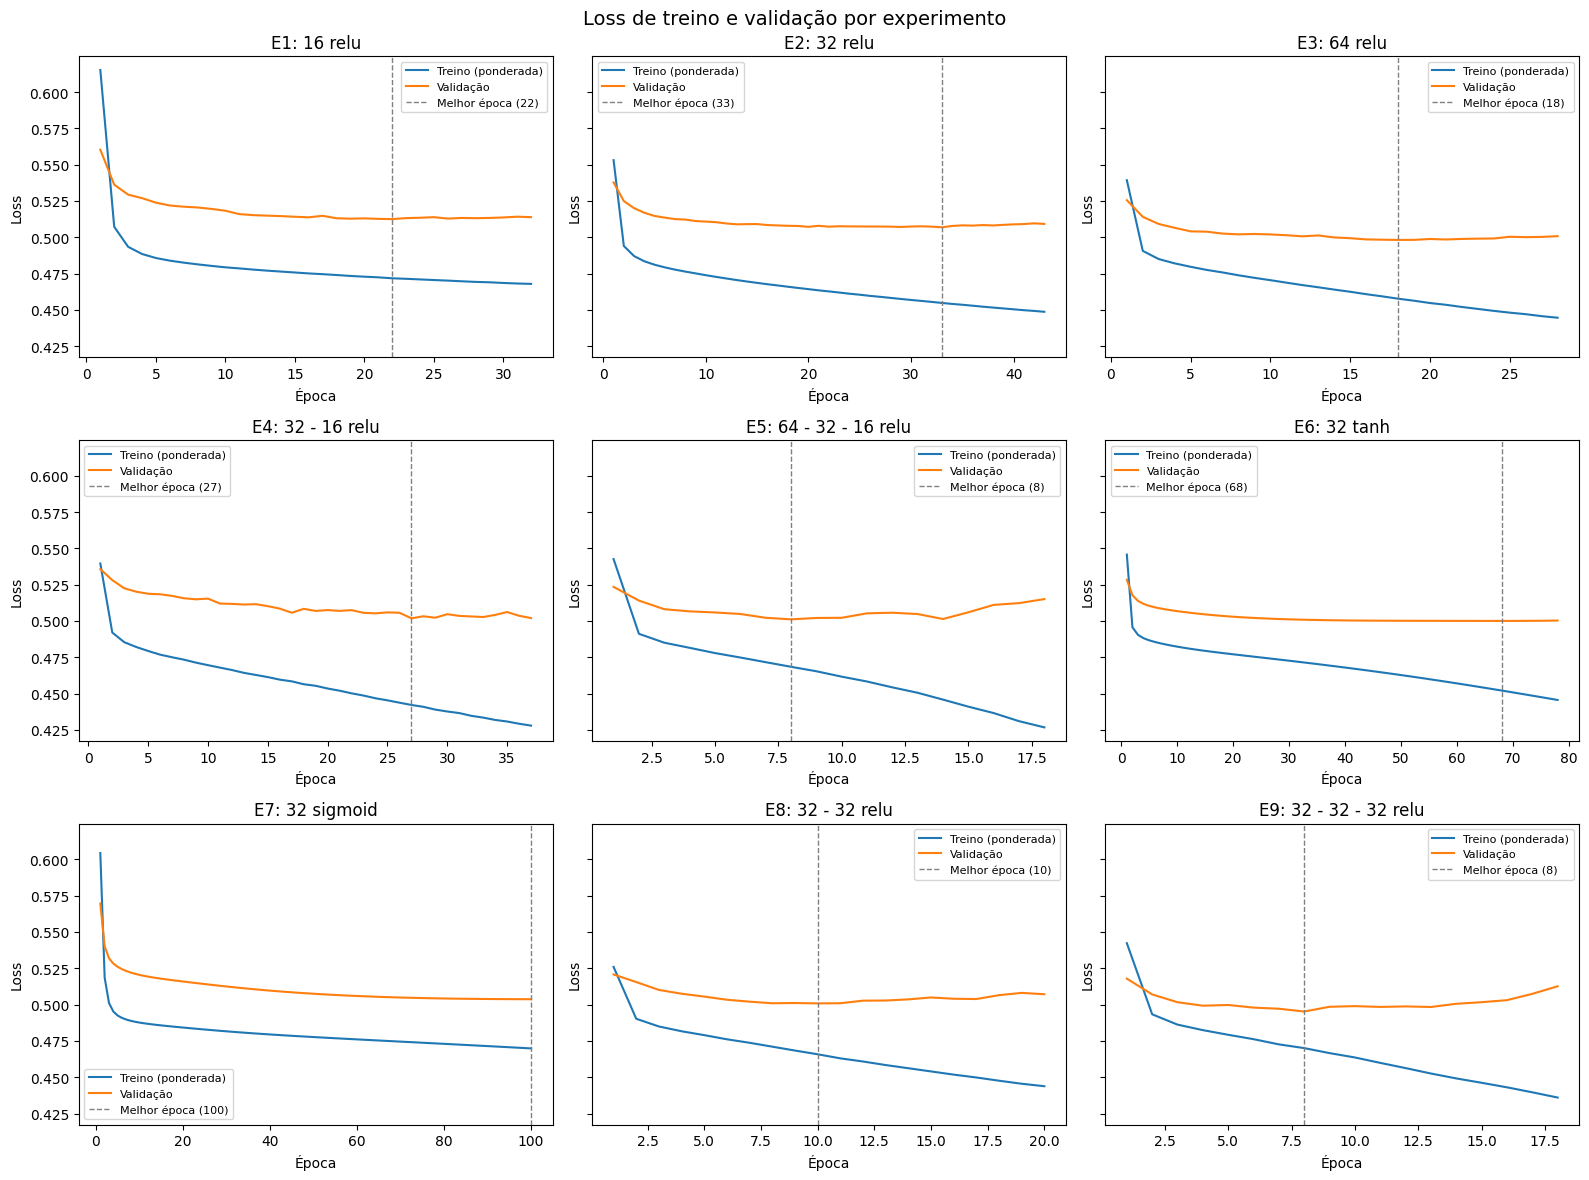

In [ ]:
# Curvas de loss por época (treino ponderado pelos pesos de classe; validação sem pesos)
fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharey=True)
for ax, (id_exp, hist) in zip(axes.ravel(), historicos.items()):
    epocas = range(1, len(hist["loss"]) + 1)
    ax.plot(epocas, hist["loss"], label="Treino (ponderada)")
    ax.plot(epocas, hist["val_loss"], label="Validação")
    melhor = resultados.loc[id_exp, "Melhor época"]
    ax.axvline(melhor, color="gray", linestyle="--", linewidth=1, label=f"Melhor época ({melhor})")
    linha = resultados.loc[id_exp]
    ax.set_title(f"{id_exp}: {linha['Neurônios por camada']} {linha['Ativação']}")
    ax.set_xlabel("Época")
    ax.set_ylabel("Loss")
    ax.legend(fontsize=8)
plt.suptitle("Loss de treino e validação por experimento", fontsize=14)
plt.tight_layout()
plt.show()

## Comparações controladas

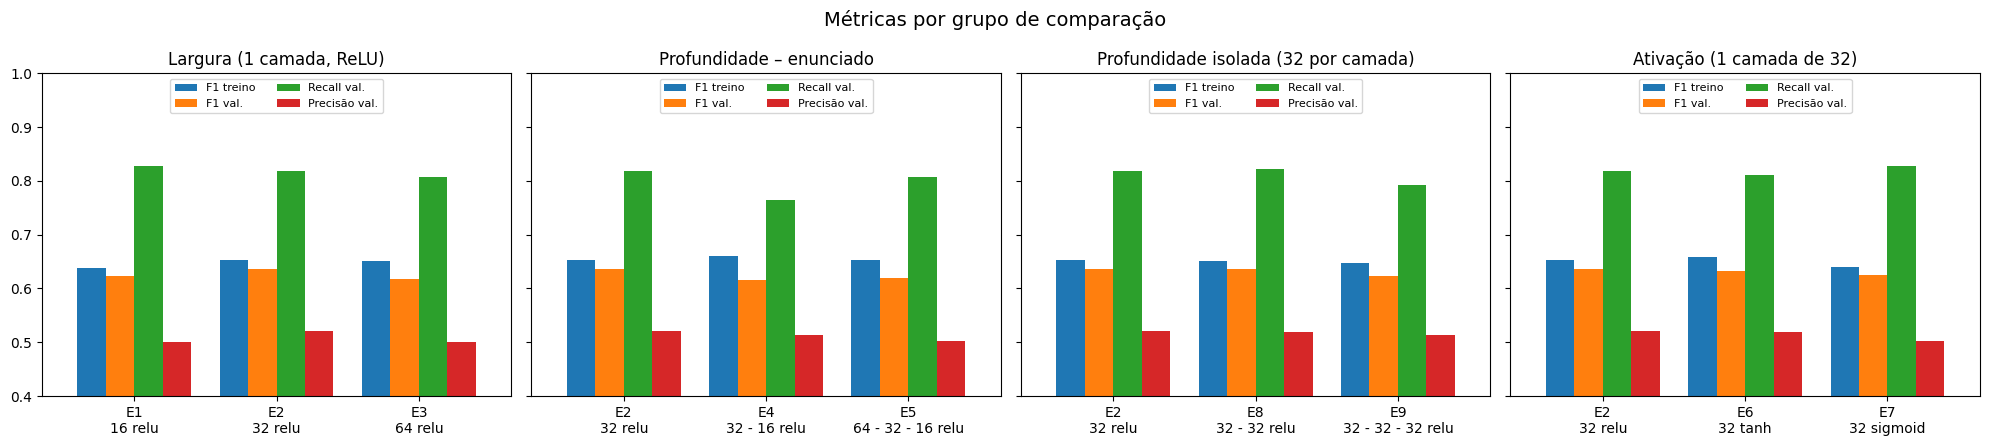

In [ ]:
# Comparações controladas: largura, profundidade e ativação
GRUPOS = {
    "Largura (1 camada, ReLU)": ["E1", "E2", "E3"],
    "Profundidade – enunciado": ["E2", "E4", "E5"],
    "Profundidade isolada (32 por camada)": ["E2", "E8", "E9"],
    "Ativação (1 camada de 32)": ["E2", "E6", "E7"],
}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, (titulo, ids) in zip(axes, GRUPOS.items()):
    sub = resultados.loc[ids, ["F1 treino", "F1", "Recall", "Precisão"]]
    sub.columns = ["F1 treino", "F1 val.", "Recall val.", "Precisão val."]
    sub.index = [f"{i}\n{resultados.loc[i, 'Neurônios por camada']} {resultados.loc[i, 'Ativação']}" for i in ids]
    sub.plot(kind="bar", ax=ax, rot=0, width=0.8)
    ax.set_title(titulo)
    ax.set_ylim(0.4, 1.0)
    ax.legend(fontsize=8, loc="upper center", ncol=2)
plt.suptitle("Métricas por grupo de comparação", fontsize=14)
plt.tight_layout()
plt.show()

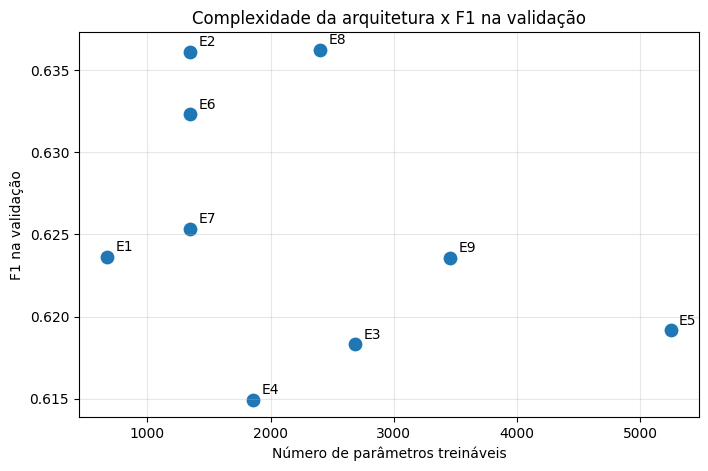

In [ ]:
# Complexidade x desempenho: o ganho compensa o número de parâmetros?
plt.figure(figsize=(8, 5))
plt.scatter(resultados["Parâmetros"], resultados["F1"], s=80)
for id_exp, linha in resultados.iterrows():
    plt.annotate(id_exp, (linha["Parâmetros"], linha["F1"]),
                 textcoords="offset points", xytext=(6, 4))
plt.xlabel("Número de parâmetros treináveis")
plt.ylabel("F1 na validação")
plt.title("Complexidade da arquitetura x F1 na validação")
plt.grid(alpha=0.3)
plt.show()

## Matrizes de confusão na validação

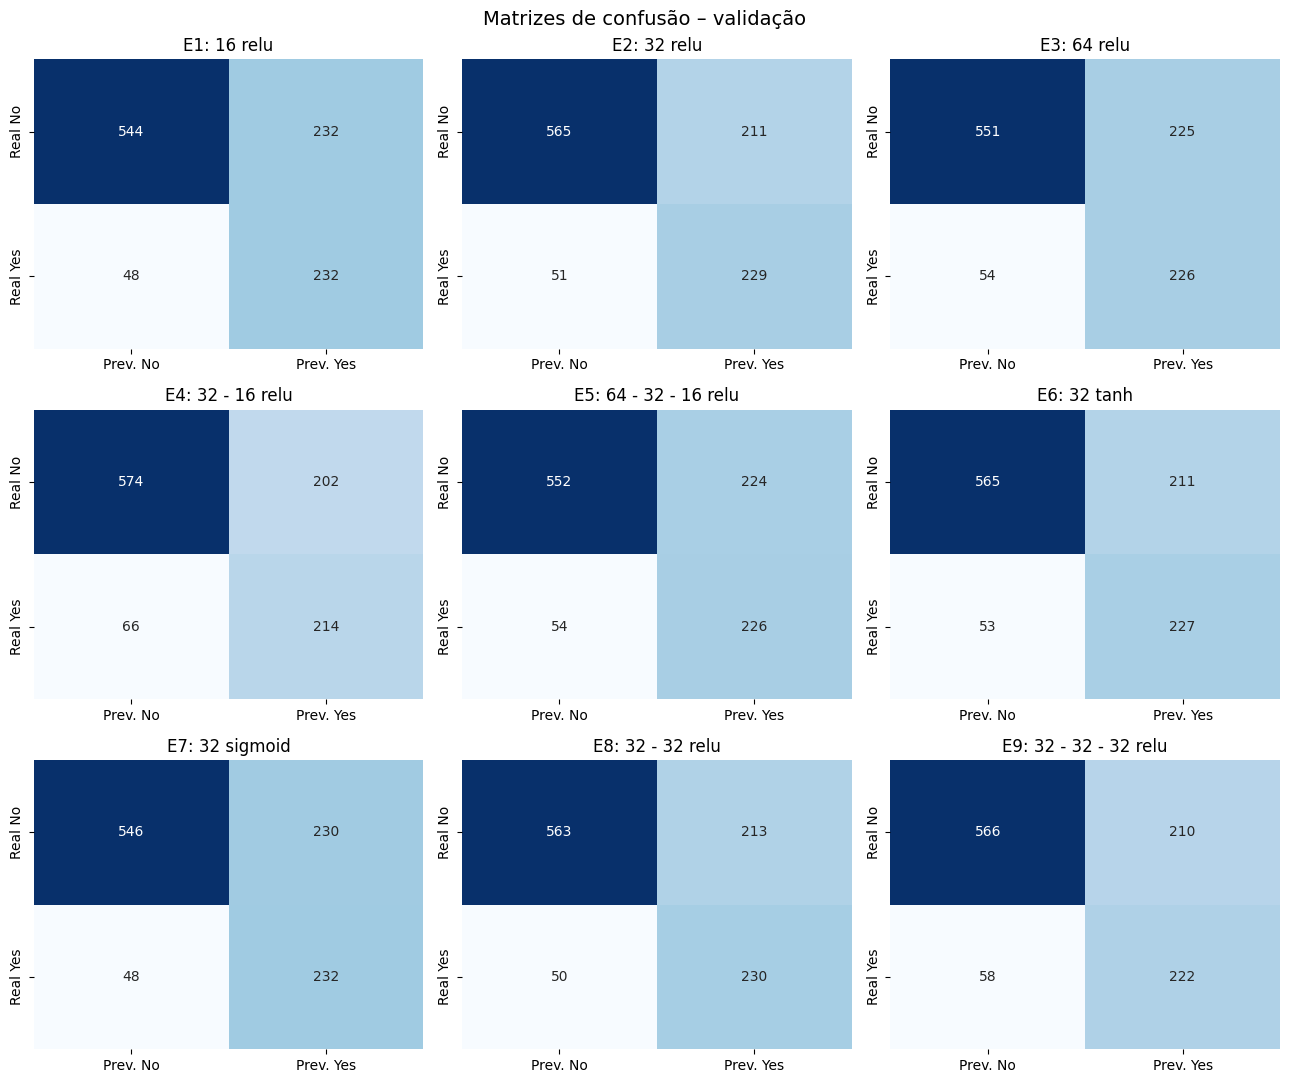

In [ ]:
# Matrizes de confusão na validação
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for ax, (id_exp, linha) in zip(axes.ravel(), resultados.iterrows()):
    sns.heatmap(linha["Matriz val."], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Prev. No", "Prev. Yes"], yticklabels=["Real No", "Real Yes"])
    ax.set_title(f"{id_exp}: {linha['Neurônios por camada']} {linha['Ativação']}")
plt.suptitle("Matrizes de confusão – validação", fontsize=14)
plt.tight_layout()
plt.show()

## Critério de seleção

O erro mais grave neste problema é o **falso negativo**: um cliente que vai cancelar e não é identificado, sem chance de ação de retenção. Um falso positivo custa menos (uma ação de retenção para quem ficaria de qualquer forma). Por isso a acurácia não é usada como critério: um modelo que prevê "não cancela" para todos teria 73,5% de acurácia e recall zero.

A métrica principal é o **F1 da classe positiva**, que equilibra recall e precisão. Diferenças menores que 0,01 no F1 são tratadas como empate, porque estão dentro da variação esperada entre treinos; no empate, vence a arquitetura **mais simples**.

In [ ]:
# Regra de seleção definida ANTES de olhar o teste:
# 1) F1 da classe positiva na validação é a métrica principal;
# 2) consideram-se empatados os modelos a até 0,01 do melhor F1;
# 3) entre os empatados, escolhe-se o de menos parâmetros (e, se ainda empatar, o de maior F1).
TOLERANCIA = 0.01

melhor_f1 = resultados["F1"].max()
candidatos = resultados[resultados["F1"] >= melhor_f1 - TOLERANCIA].copy()
candidatos["Gap F1"] = candidatos["F1 treino"] - candidatos["F1"]
candidatos = candidatos.sort_values(["Parâmetros", "F1"], ascending=[True, False])

print(f"Melhor F1 na validação: {melhor_f1:.4f}")
print(f"Candidatos (F1 >= {melhor_f1 - TOLERANCIA:.4f}):")
print(candidatos[["Neurônios por camada", "Ativação", "Parâmetros", "F1", "Recall",
                  "Precisão", "Gap F1"]].round(4))

ESCOLHIDO = candidatos.index[0]
print(f"\nArquitetura escolhida: {ESCOLHIDO} "
      f"({resultados.loc[ESCOLHIDO, 'Neurônios por camada']} neurônios, "
      f"{resultados.loc[ESCOLHIDO, 'Ativação']})")

Melhor F1 na validação: 0.6362
Candidatos (F1 >= 0.6262):
   Neurônios por camada Ativação  Parâmetros      F1  Recall  Precisão  Gap F1
ID                                                                            
E2                   32     relu        1345  0.6361  0.8179    0.5205  0.0177
E6                   32     tanh        1345  0.6323  0.8107    0.5183  0.0256
E8              32 - 32     relu        2401  0.6362  0.8214    0.5192  0.0143

Arquitetura escolhida: E2 (32 neurônios, relu)


## Análise dos resultados

**Efeito da largura (E1 → E2 → E3; Questão 5).** Passar de 16 para 32 neurônios aumentou o F1 de 0,624 para 0,636. Dobrar para 64 não trouxe ganho (F1 0,618) e aumentou a diferença entre treino e validação (gap de F1 de 0,015 para 0,033), um sinal de que a capacidade extra passou a ser usada para memorizar o treino. A loss de validação caiu levemente com a largura (0,513 → 0,498), mas essa melhora nas probabilidades não se converteu em melhor classificação no limiar de 0,5.

**Efeito da profundidade (E2 → E4 → E5 e E2 → E8 → E9; Questão 6).** Mais camadas não melhoraram o desempenho. Com largura fixa em 32 (comparação isolada), 2 camadas empataram com 1 camada (F1 0,636 nos dois casos) usando quase o dobro de parâmetros, e 3 camadas pioraram (F1 0,618, recall 0,782 contra 0,818). Nas arquiteturas do enunciado, E4 (F1 0,615) e E5 (F1 0,619) também ficaram abaixo de E2. As redes mais profundas atingiram a melhor época mais cedo (8 a 11 épocas em E5, E8 e E9) e tiveram os maiores gaps (0,045 em E4 e 0,038 em E9).

**Efeito da ativação (E2 → E6 → E7; Questão 7).** ReLU (F1 0,636) e tanh (0,632) ficaram praticamente empatadas, mas a tanh precisou de 78 épocas contra 43 da ReLU. A sigmoid ficou abaixo (0,625) e chegou às 100 épocas ainda melhorando, sem acionar o early stopping. Isso é coerente com a saturação da sigmoid nas camadas ocultas: os gradientes ficam pequenos e o aprendizado fica mais lento.

**Underfitting e overfitting (Questão 8).** Nenhum modelo mostrou overfitting forte: os gaps de F1 ficaram abaixo de 0,05, e o early stopping restaurou os pesos da melhor época de validação. Os sinais mais claros de sobreajuste estão nas redes mais profundas (E4 e E9). E7 mostra o caso oposto: com o limite de 100 épocas, a rede sigmoid ainda não havia convergido, um indício de underfitting por convergência lenta. O fato de todas as arquiteturas ficarem entre 0,61 e 0,64 de F1 sugere que o limite está mais nas informações da base do que na capacidade da rede.

**Complexidade × ganho.** O modelo com mais parâmetros (E5, 5.249) não superou o E2 (1.345). Aumentar a complexidade não trouxe ganho que justificasse o custo.

**Arquitetura escolhida (Questão 9): E2 — 1 camada oculta com 32 neurônios, ReLU.** E2 e E8 empataram no maior F1 de validação (0,636), e E6 ficou dentro da margem de 0,01. Entre eles, E2 é o mais simples (1.345 parâmetros, contra 2.401 do E8), tem gap baixo (0,018) e mantém um recall alto para a classe positiva (0,818): de 280 clientes que cancelaram na validação, identificou 229. O custo é a precisão em torno de 0,52, ou seja, cerca de metade dos clientes sinalizados não cancelaria. Para uma ação de retenção, essa troca é aceitável, porque perder um cliente é mais caro do que contatar um cliente que ficaria.

# Etapa 6 - Avaliação final no teste


**Arquitetura escolhida na validação: E2** — 1 camada oculta com 32 neurônios, ativação ReLU.

**Motivo:** a escolha usou apenas a validação. E2 e E8 empataram no maior F1 (0,636), e E2 é a mais simples (1.345 parâmetros contra 2.401). Ela tem gap de F1 treino × validação baixo (0,018) e recall alto na classe positiva (0,818): dos 280 clientes que cancelaram na validação, identificou 229. O custo é a precisão em torno de 0,52, aceitável porque o falso negativo (perder o cliente sem ação de retenção) é o erro mais caro. Mais camadas e mais neurônios não trouxeram ganho que justificasse a complexidade.

O modelo avaliado abaixo é o mesmo treinado na Etapa 4, sem retreino. Se o resultado no teste for ruim, ele será reportado e discutido, e **não** será usado para trocar o modelo.

# Célula 2: Avaliação no teste

In [ ]:
# Mesmo modelo da Etapa 4 (sem retreinar) e mesmo limiar da validação
assert ESCOLHIDO == "E2", "Atualize o Markdown se a escolha mudar"
modelo_final = modelos[ESCOLHIDO]

m_val   = avaliar(modelo_final, X_val_proc,  y_val_arr)
m_teste = avaliar(modelo_final, X_test_proc, y_test_arr)

chaves = [("Loss", "loss"), ("Acurácia", "acuracia"), ("Precisão", "precisao"),
          ("Recall", "recall"), ("F1", "f1")]

comparacao = pd.DataFrame({
    "Validação": [m_val[k] for _, k in chaves],
    "Teste":     [m_teste[k] for _, k in chaves],
}, index=[nome for nome, _ in chaves])
comparacao["Diferença (teste − val.)"] = comparacao["Teste"] - comparacao["Validação"]

print(f"Modelo avaliado: {ESCOLHIDO} | limiar = {CONFIG['limiar_decisao']}")
comparacao.round(4)

Modelo avaliado: E2 | limiar = 0.5


,Validação,Teste,Diferença (teste − val.)
Loss,0.5069,0.4806,-0.0262
Acurácia,0.7519,0.7389,-0.0130
Precisão,0.5205,0.5059,-0.0146
Recall,0.8179,0.7651,-0.0527
F1,0.6361,0.6091,-0.0270


# Célula 3: Matrizes de confusão lado a lado

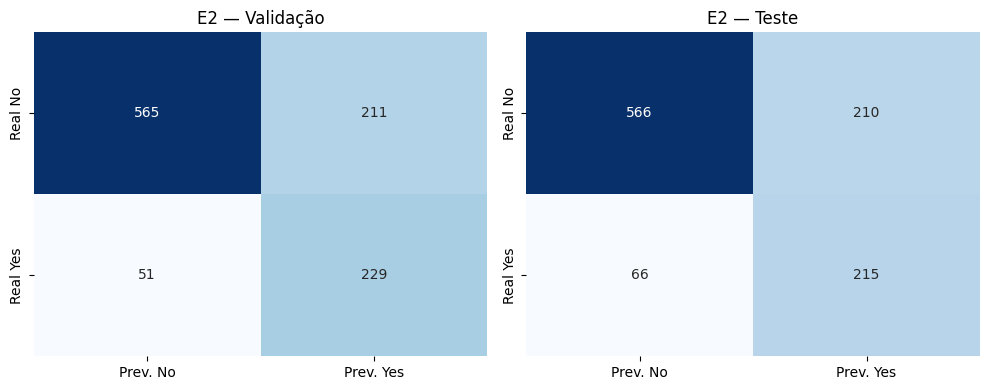

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (titulo, m) in zip(axes, [("Validação", m_val), ("Teste", m_teste)]):
    sns.heatmap(m["matriz"], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Prev. No", "Prev. Yes"], yticklabels=["Real No", "Real Yes"])
    ax.set_title(f"{ESCOLHIDO} — {titulo}")
plt.tight_layout()
plt.show()

# Célula 4: Matriz de confusão traduzida para o problema

In [ ]:
vn, fp, fn, vp = m_teste["matriz"].ravel()
n_pos, n_neg = vp + fn, vn + fp

print(f"• Dos {n_pos} clientes que cancelaram no teste, o modelo identificou {vp} "
      f"(recall = {vp/n_pos:.1%}); {fn} passaram sem ser detectados (falsos negativos).")
print(f"• Dos {vp + fp} clientes que o modelo sinalizou como risco de cancelamento, "
      f"{vp} realmente cancelaram (precisão = {vp/(vp+fp):.1%}); "
      f"{fp} eram clientes que ficariam (falsos positivos).")
print(f"• Dos {n_neg} clientes que permaneceram, {vn} foram corretamente reconhecidos "
      f"({vn/n_neg:.1%}).")
print(f"• Em termos de 100 clientes que cancelaram: o modelo identificou {vp/n_pos*100:.0f}.")

• Dos 281 clientes que cancelaram no teste, o modelo identificou 215 (recall = 76.5%); 66 passaram sem ser detectados (falsos negativos).
• Dos 425 clientes que o modelo sinalizou como risco de cancelamento, 215 realmente cancelaram (precisão = 50.6%); 210 eram clientes que ficariam (falsos positivos).
• Dos 776 clientes que permaneceram, 566 foram corretamente reconhecidos (72.9%).
• Em termos de 100 clientes que cancelaram: o modelo identificou 77.


# Célula 5 (Markdown): Consistência

## Consistência entre validação e teste

O modelo E2 foi avaliado no conjunto de teste uma única vez, sem retreino e com o mesmo limiar de 0,5 da validação.

| Métrica | Validação | Teste | Diferença |
| --- | --- | --- | --- |
| Loss | 0,5069 | 0,4806 | −0,0262 |
| Acurácia | 0,7519 | 0,7389 | −0,0130 |
| Precisão | 0,5205 | 0,5059 | −0,0146 |
| Recall | 0,8179 | 0,7651 | −0,0527 |
| F1 | 0,6361 | 0,6091 | −0,0270 |

**Consistência.** As diferenças foram pequenas: a acurácia caiu 1,3 ponto percentual, a precisão 1,5 e o F1 2,7 (de 0,636 para 0,609). A loss no teste (0,481) ficou até abaixo da de validação (0,507), então as probabilidades previstas não pioraram em dados novos. Isso indica boa generalização e sugere que a escolha da E2 não ficou ajustada demais à validação. A queda mais visível foi no recall, de 0,818 para 0,765 (−5,3 pontos): os falsos negativos passaram de 51 para 66. Como cada conjunto tem cerca de 280 clientes que cancelaram, uma diferença dessa ordem (cerca de 15 clientes) é compatível com a variação esperada entre amostras diferentes, mas é o ponto mais sensível do resultado. Não houve troca de modelo após ver o teste. Este resultado é a estimativa final do desempenho da E2 em dados não utilizados nas decisões de modelagem.

**Matriz de confusão no contexto do problema.** No teste havia 281 clientes que cancelaram e 776 que permaneceram.

- De 100 clientes que cancelaram, o modelo identificou cerca de 77 (215 de 281; recall = 76,5%). Os outros 66 não foram detectados (falsos negativos), e este é o erro mais grave, pois o cliente é perdido sem chance de ação de retenção.
- O modelo sinalizou 425 clientes como risco de cancelamento, e 215 deles realmente cancelaram (precisão = 50,6%). Os outros 210 eram clientes que ficariam (falsos positivos), o que representa um custo de contato desnecessário, menos grave que perder o cliente.
- Dos 776 clientes que permaneceram, 566 foram corretamente reconhecidos (72,9%).

Para uma ação de retenção, essa troca é aceitável: o modelo encontra mais de três quartos dos clientes que cancelariam, ao custo de contatar cerca de um cliente a mais que ficaria para cada cliente que realmente iria cancelar.

**Limitações.** A precisão fica em torno de 0,5, então metade das ações de retenção seria direcionada a clientes que não cancelariam. O limiar de decisão ficou fixo em 0,5 e não foi otimizado, e o `class_weight` usado no treino favorece o recall em detrimento da precisão. O conjunto de teste tem 1.057 clientes, então pequenas diferenças entre validação e teste estão dentro da variação esperada. Além disso, todas as arquiteturas testadas ficaram entre 0,61 e 0,64 de F1 na validação, o que sugere que o limite de desempenho está mais nas informações da base do que na capacidade da rede.